In [ ]:
import hashlib
import os
import platform
import sys
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080131
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[Conda 环境] {CONDA_ENV or '未检测到 Conda 环境'}")
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")
print(f"[Python] {sys.version.split()[0]}")

if not CONDA_ENV or CONDA_ENV.lower() == "base":
    print("[提示] 请在 Notebook 内核选择器中切换到独立 Conda 环境。")

[Conda 环境] exp01
[学号] 20244080131
[机器指纹] 73b9d34140867d67
[RUN_ID] 20244080131-73b9d34140867d67
[Python] 3.11.16


# 随机矩阵与半圆定律

Wigner 矩阵的上三角元素独立服从均值为 0、方差为 $1/n$ 的正态分布，再关于主对角线镜像构造对称矩阵。半圆密度为 $f(x)=\sqrt{4-x^2}/(2\pi)$（$|x|\le 2$），区间外为 0。

In [2]:
import numpy as np


def wigner_density(x):
    if abs(x) <= 2:
        return float(np.sqrt(4 - x**2) / (2 * np.pi))
    return 0.0


def generate_wigner(n):
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是正整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    upper = np.triu(np.random.normal(0.0, 1 / np.sqrt(n), size=(n, n)))
    return upper + upper.T - np.diag(np.diag(upper))


def get_spectrum(matrix):
    return np.linalg.eigvalsh(matrix)


assert isinstance(wigner_density(np.int64(0)), float)
assert np.isclose(wigner_density(0), 1 / np.pi)
assert wigner_density(2.1) == 0.0
small_wigner = generate_wigner(5)
assert small_wigner.shape == (5, 5)
assert np.allclose(small_wigner, small_wigner.T)
assert np.all(np.diff(get_spectrum(small_wigner)) >= 0)

for invalid_n, expected_error in [(0, ValueError), (-2, ValueError), (2.5, TypeError)]:
    try:
        generate_wigner(invalid_n)
    except expected_error:
        pass
    else:
        raise AssertionError(f"generate_wigner({invalid_n}) 应抛出 {expected_error.__name__}")

print("半圆密度 f(0):", wigner_density(0))
print("5x5 Wigner 矩阵对称:", np.allclose(small_wigner, small_wigner.T))
print("5x5 特征值（非递减）:", get_spectrum(small_wigner))


半圆密度 f(0): 0.3183098861837907
5x5 Wigner 矩阵对称: True
5x5 特征值（非递减）: [-1.07394915 -0.15626132  0.64778083  1.11882253  1.57649033]


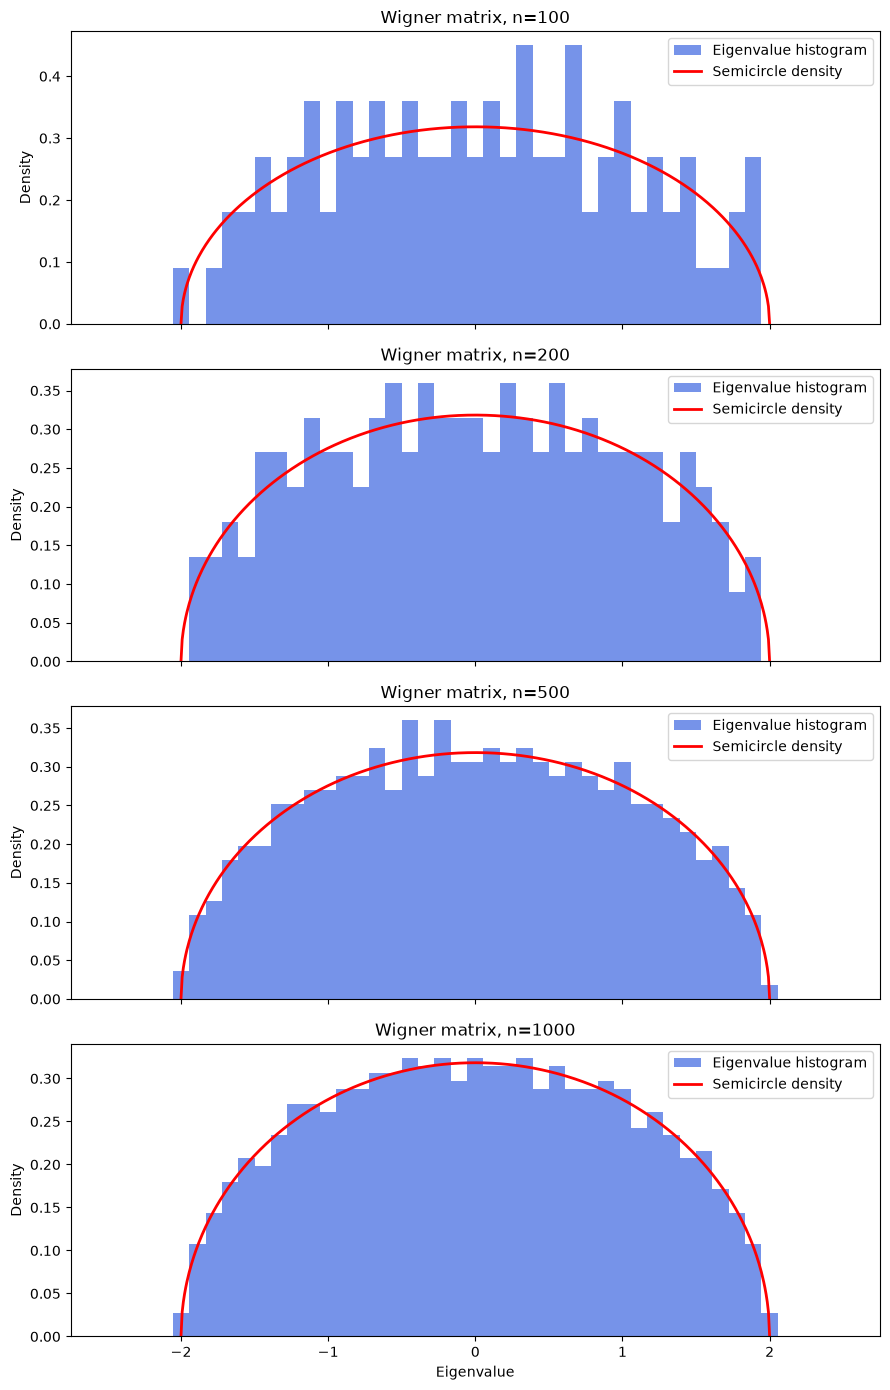

In [15]:
import matplotlib.pyplot as plt

np.random.seed(42)
plot_sizes = [100, 200, 500, 1000]
x_curve = np.linspace(-2, 2, 500)
y_curve = np.sqrt(np.maximum(0, 4 - x_curve**2)) / (2 * np.pi)
fig, axes = plt.subplots(len(plot_sizes), 1, figsize=(9, 14), sharex=True)

for ax, n in zip(axes, plot_sizes):
    eigenvalues = get_spectrum(generate_wigner(n))
    ax.hist(
        eigenvalues,
        bins=45,
        range=(-2.5, 2.5),
        density=True,
        color="royalblue",
        alpha=0.72,
        label="Eigenvalue histogram",
    )
    ax.plot(x_curve, y_curve, color="red", linewidth=2, label="Semicircle density")
    ax.set_title(f"Wigner matrix, n={n}")
    ax.set_ylabel("Density")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Eigenvalue")
fig.tight_layout()
plt.show()

从图中可见，$n=100$ 时有限样本波动较明显；约从 $n=500$ 开始，直方图与半圆密度已有较好吻合，$n=1000$ 时曲线轮廓更平滑。单次随机抽样会有差异。

# Conway 的生命游戏

每一步先从原棋盘统计八个方向的环绕邻居，再同时应用生存和复活规则，避免边遍历边修改造成状态污染。棋盘只接受二维 NumPy 数组，且元素必须为 0 或 1。

初始 blinker:
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
演化一步后:
 [[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
两步后恢复原状: True


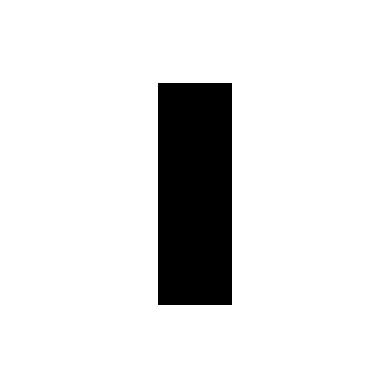

In [16]:
from matplotlib.colors import ListedColormap


def is_valid_board(board):
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    if board.shape[0] == 0 or board.shape[1] == 0:
        return False
    return bool(np.isin(board, [0, 1]).all())


def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("board 必须是仅包含 0 和 1 的非空二维 NumPy 数组")

    neighbors = np.zeros(board.shape, dtype=np.int16)
    for row_shift in (-1, 0, 1):
        for col_shift in (-1, 0, 1):
            if row_shift == 0 and col_shift == 0:
                continue
            neighbors += np.roll(
                board, shift=(row_shift, col_shift), axis=(0, 1)
            )

    survives = (board == 1) & ((neighbors == 2) | (neighbors == 3))
    born = (board == 0) & (neighbors == 3)
    return (survives | born).astype(np.uint8)


def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("board 必须是仅包含 0 和 1 的非空二维 NumPy 数组")

    fig, ax = plt.subplots()
    ax.imshow(
        board,
        cmap=ListedColormap(["white", "black"]),
        vmin=0,
        vmax=1,
        interpolation="none",
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_axis_off()
    ax.set_aspect("equal")
    return fig, ax


blinker = np.zeros((5, 5), dtype=np.uint8)
blinker[2, 1:4] = 1
blinker_next = gol_step(blinker)
blinker_after_two = gol_step(blinker_next)
assert is_valid_board(blinker)
assert not is_valid_board(np.array([[0, 2]]))
assert not is_valid_board(np.array([0, 1]))
assert np.array_equal(blinker_after_two, blinker)
print("初始 blinker:\n", blinker)
print("演化一步后:\n", blinker_next)
print("两步后恢复原状:", np.array_equal(blinker_after_two, blinker))
draw_gol_board(blinker_next)
plt.show()

# 使用 pandas DataFrame 分析 Iris 数据

本 CSV 没有花卉种类列，但含连续的 0–149 原始行索引。代码仅在确认数据恰有 150 行且索引完整连续后，才按标准 Iris 数据顺序补回三类标签。第 35、38 行对应索引 34、37；下载文件中索引 50 的花瓣宽度也写成了 14，代码会在该行其余测量值完全吻合时将它更正为 1.4。

In [8]:
from pathlib import Path
import re
import pandas as pd

iris_path = Path("iris.csv")

if not iris_path.exists():
    print(f"尚未找到 {iris_path.resolve()}。请将题目指定的 iris.csv 放到 Notebook 同一目录，再运行本单元。")
else:
    iris = pd.read_csv(iris_path)

    def normalize_column_name(column):
        return re.sub(r"[^a-z0-9]", "", str(column).lower())

    available_columns = {
        normalize_column_name(column): column for column in iris.columns
    }
    column_aliases = {
        "sepal_length": ["sepallength", "sepallengthcm"],
        "sepal_width": ["sepalwidth", "sepalwidthcm"],
        "petal_length": ["petallength", "petallengthcm"],
        "petal_width": ["petalwidth", "petalwidthcm"],
        "species": ["species", "class", "variety"],
    }
    rename_columns = {}
    for standard_name, aliases in column_aliases.items():
        source_column = next(
            (available_columns[alias] for alias in aliases if alias in available_columns),
            None,
        )
        if source_column is not None:
            rename_columns[source_column] = standard_name

    iris = iris.rename(columns=rename_columns)

    if "species" not in iris.columns:
        index_column = next(
            (
                column for column in iris.columns
                if normalize_column_name(column) in {"", "index", "unnamed0"}
            ),
            None,
        )
        if index_column is None or len(iris) != 150:
            raise ValueError(
                "CSV 缺少 species 列，且不符合标准 Iris 数据的 150 行索引格式，无法可靠补回类别。"
            )
        source_index = pd.to_numeric(iris[index_column], errors="coerce").to_numpy()
        if not np.array_equal(source_index, np.arange(150)):
            raise ValueError("CSV 的原始索引不是连续的 0–149，无法可靠补回类别。")

        iris["species"] = [
            "setosa" if row_index < 50
            else "versicolor" if row_index < 100
            else "virginica"
            for row_index in source_index
        ]
        iris = iris.drop(columns=[index_column])
        print("已根据标准 Iris 数据的连续原始索引补回 species 标签。")

    required_columns = [
        "sepal_length", "sepal_width", "petal_length", "petal_width", "species"
    ]
    missing_columns = [column for column in required_columns if column not in iris.columns]
    if missing_columns:
        raise ValueError(f"CSV 缺少必要列: {missing_columns}; 当前列名为 {list(iris.columns)}")
    iris = iris[required_columns].copy()

    print("数据点数量:", len(iris))
    print("列名:", iris.columns.tolist())
    print("各列数据类型:\n", iris.dtypes)
    print("花卉种类数:", iris["species"].nunique())
    print("花卉种类:", sorted(iris["species"].dropna().unique()))

    column_descriptions = {
        "species": "花卉种类",
        "petal_length": "花瓣长度",
        "petal_width": "花瓣宽度",
        "sepal_length": "萼片长度",
        "sepal_width": "萼片宽度",
    }
    print("列名、含义与数据类型:")
    for column, description in column_descriptions.items():
        print(f"{description} ({column}): {iris[column].dtype}")

    if len(iris) <= 37:
        raise ValueError("数据行数不足，无法更正索引 34 和 37")
    iris.loc[34, required_columns] = [4.9, 3.1, 1.5, 0.2, "setosa"]
    iris.loc[37, required_columns] = [4.9, 3.6, 1.4, 0.1, "setosa"]
    print("更正后的第 35、38 行:\n", iris.loc[[34, 37]])

    if len(iris) > 50:
        index_50_measurements = iris.loc[50, [
            "sepal_length", "sepal_width", "petal_length", "petal_width"
        ]].tolist()
        if index_50_measurements == [7.0, 3.2, 4.7, 14.0]:
            iris.loc[50, "petal_width"] = 1.4
            print("另将 index 50 的 petal_width 从 14 更正为 1.4(原文件小数点遗漏）。")

    iris["Petal.Ratio"] = iris["petal_length"] / iris["petal_width"]
    iris["Sepal.Ratio"] = iris["sepal_length"] / iris["sepal_width"]
    iris.to_csv("iris_corrected.csv", index=False)
    print("已保存 iris_corrected.csv")

    ratio_summary = iris.groupby("species").agg({
        "Petal.Ratio": ["mean", "median", "min", "max", "std"],
        "Sepal.Ratio": ["mean", "median", "min", "max", "std"],
    })
    ratio_summary = ratio_summary.rename(
        columns={
            "Petal.Ratio": "花瓣比值 (Petal.Ratio)",
            "Sepal.Ratio": "萼片比值 (Sepal.Ratio)",
        },
        level=0,
    ).rename(
        columns={
            "mean": "平均值",
            "median": "中位数",
            "min": "最小值",
            "max": "最大值",
            "std": "标准差",
        },
        level=1,
    )
    statistic_order = ["平均值", "中位数", "最小值", "最大值", "标准差"]
    ratio_order = ["花瓣比值 (Petal.Ratio)", "萼片比值 (Sepal.Ratio)"]
    ratio_summary = ratio_summary.reorder_levels([1, 0], axis=1).reindex(
        columns=pd.MultiIndex.from_product([statistic_order, ratio_order])
    )
    print("各花卉种类的比值统计：")
    display(
        ratio_summary.style
        .format("{:.4f}")
        .set_caption("各花卉种类比值统计（平均值、中位数、最小值、最大值、标准差）")
    )

已根据标准 Iris 数据的连续原始索引补回 species 标签。
数据点数量: 150
列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
各列数据类型:
 sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object
花卉种类数: 3
花卉种类: ['setosa', 'versicolor', 'virginica']
列名、含义与数据类型:
花卉种类 (species): str
花瓣长度 (petal_length): float64
花瓣宽度 (petal_width): float64
萼片长度 (sepal_length): float64
萼片宽度 (sepal_width): float64
更正后的第 35、38 行:
     sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa
另将 index 50 的 petal_width 从 14 更正为 1.4(原文件小数点遗漏）。
已保存 iris_corrected.csv
各花卉种类的比值统计：
